[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wellingtonmnf/pos-graduacao-ia-ciencia-dados/blob/main/disciplinas/processamento-linguagem-natural/notebooks/unidade-02/analise-de-n-gramas.ipynb)


In [ ]:
# Revisão documental — 20/10/2026.
# Saídas históricas preservadas. C16/C19/C23/C26/C30/C33: os relatórios salvos usam Positive/Negative
# na ordem antiga; a fonte atual usa lb.classes_ (negative/positive). Execução integral desta revisão
# no Colab pendente.

# Preparação da dependência usada pelo adaptador Pandas.
%pip install "kagglehub[pandas-datasets]"
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Defina o nome do arquivo correto do dataset
file_path = "IMDB Dataset.csv"

# Carrega a versão 1, comparada em 2026-10-19, preservando a ordem das resenhas.
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/versions/1",
  file_path
)

if not {"review", "sentiment"}.issubset(df.columns):
    raise ValueError("Colunas inesperadas no IMDb")
if df["review"].isna().any() or not df["review"].map(lambda x: isinstance(x, str) and bool(x.strip())).all():
    raise ValueError("Resenhas ausentes ou inválidas")
if df["sentiment"].isna().any() or not df["sentiment"].isin(["positive", "negative"]).all():
    raise ValueError("Rótulos inesperados no IMDb")

print("Primeiros 5 registros:")
display(df.head())

Using Colab cache for faster access to the 'imdb-dataset-of-50k-movie-reviews' dataset.
Primeiros 5 registros:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [ ]:
df.isnull().sum()

,0
review,0
sentiment,0


In [ ]:
df['sentiment'].value_counts()

,count
sentiment,
positive,25000
negative,25000


<Axes: title={'center': 'Quantidade por Tipo'}, xlabel='sentiment'>

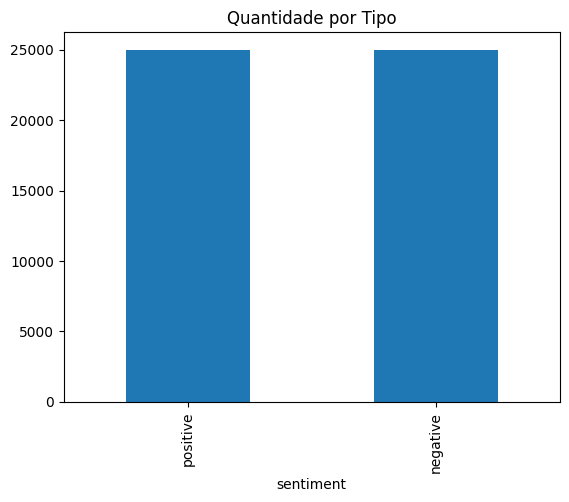

In [ ]:
df["sentiment"].value_counts().plot.bar(title='Quantidade por Tipo',rot=90)

In [ ]:
!pip install nltk
import nltk
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [ ]:
exemplo = df['review'].values[0]
print(exemplo)
print(len(exemplo.split()))

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due to the fac

In [ ]:
from nltk.tokenize import word_tokenize
import string

stopwords = nltk.corpus.stopwords.words('english')
punctuations = list(string.punctuation)

def prepara(texto):
    palavras = [i for i in word_tokenize(texto, language='english') if i not in punctuations]
    palavras = [i for i in palavras if i not in stopwords]
    return palavras

exemplo_preparado = prepara(exemplo)
print(exemplo_preparado)
print(len(exemplo_preparado))

['One', 'reviewers', 'mentioned', 'watching', '1', 'Oz', 'episode', "'ll", 'hooked', 'They', 'right', 'exactly', 'happened', 'me.', 'br', 'br', 'The', 'first', 'thing', 'struck', 'Oz', 'brutality', 'unflinching', 'scenes', 'violence', 'set', 'right', 'word', 'GO', 'Trust', 'show', 'faint', 'hearted', 'timid', 'This', 'show', 'pulls', 'punches', 'regards', 'drugs', 'sex', 'violence', 'Its', 'hardcore', 'classic', 'use', 'word.', 'br', 'br', 'It', 'called', 'OZ', 'nickname', 'given', 'Oswald', 'Maximum', 'Security', 'State', 'Penitentary', 'It', 'focuses', 'mainly', 'Emerald', 'City', 'experimental', 'section', 'prison', 'cells', 'glass', 'fronts', 'face', 'inwards', 'privacy', 'high', 'agenda', 'Em', 'City', 'home', 'many', '..', 'Aryans', 'Muslims', 'gangstas', 'Latinos', 'Christians', 'Italians', 'Irish', '....', 'scuffles', 'death', 'stares', 'dodgy', 'dealings', 'shady', 'agreements', 'never', 'far', 'away.', 'br', 'br', 'I', 'would', 'say', 'main', 'appeal', 'show', 'due', 'fact', 

In [ ]:
from nltk.tokenize import word_tokenize
import string
stopwords = nltk.corpus.stopwords.words('english')
punctuations = list(string.punctuation)
TAMANHO_MIMINO = 1
IGNORAR = ['...', 'br','.so','\'ll']

from nltk.stem import SnowballStemmer
stemmer = SnowballStemmer('english')
def prepara(texto):
    palavras = [i for i in word_tokenize(texto, language='english') if i not in punctuations]
    palavras = [i for i in palavras if i not in stopwords]
    palavras = [i for i in palavras if len(i) > TAMANHO_MIMINO]
    palavras = [i for i in palavras if i not in IGNORAR]
    palavras = [stemmer.stem(i) for i in palavras]
    return palavras
exemplo_preparado = prepara(exemplo)
print(exemplo_preparado)
print(len(exemplo_preparado))

['one', 'review', 'mention', 'watch', 'oz', 'episod', 'hook', 'they', 'right', 'exact', 'happen', 'me.', 'the', 'first', 'thing', 'struck', 'oz', 'brutal', 'unflinch', 'scene', 'violenc', 'set', 'right', 'word', 'go', 'trust', 'show', 'faint', 'heart', 'timid', 'this', 'show', 'pull', 'punch', 'regard', 'drug', 'sex', 'violenc', 'it', 'hardcor', 'classic', 'use', 'word.', 'it', 'call', 'oz', 'nicknam', 'given', 'oswald', 'maximum', 'secur', 'state', 'penitentari', 'it', 'focus', 'main', 'emerald', 'citi', 'experiment', 'section', 'prison', 'cell', 'glass', 'front', 'face', 'inward', 'privaci', 'high', 'agenda', 'em', 'citi', 'home', 'mani', '..', 'aryan', 'muslim', 'gangsta', 'latino', 'christian', 'italian', 'irish', '....', 'scuffl', 'death', 'stare', 'dodgi', 'deal', 'shadi', 'agreement', 'never', 'far', 'away.', 'would', 'say', 'main', 'appeal', 'show', 'due', 'fact', 'goe', 'show', 'would', "n't", 'dare', 'forget', 'pretti', 'pictur', 'paint', 'mainstream', 'audienc', 'forget', 'c

In [ ]:
%%time
df['review2'] = df['review'].apply(prepara)
df['review2'] = df['review2'].apply(' '.join)

CPU times: user 3min 9s, sys: 626 ms, total: 3min 10s
Wall time: 3min 11s


In [ ]:
df.head()

,review,sentiment,review2
0,One of the other reviewers has mentioned that ...,positive,one review mention watch oz episod hook they r...
1,A wonderful little production. <br /><br />The...,positive,wonder littl product the film techniqu unassum...
2,I thought this was a wonderful way to spend ti...,positive,thought wonder way spend time hot summer weeke...
3,Basically there's a family where a little boy ...,negative,basic 's famili littl boy jake think 's zombi ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,petter mattei 's `` love time money '' visual ...


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df['review2'], df['sentiment'], test_size=0.2, random_state=0)
print('X_train shape:',X_train.shape)
print('y_train shape:',y_train.shape)
print('X_test shape:',X_test.shape)
print('y_test shape:',y_test.shape)

X_train shape: (40000,)
y_train shape: (40000,)
X_test shape: (10000,)
y_test shape: (10000,)


In [ ]:
%%time
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer(min_df=1,max_df=1.0,binary=False,ngram_range=(1,1))
bow_X_train = cv.fit_transform(X_train)
bow_X_test = cv.transform(X_test)
print('bow_X_train shape:', bow_X_train.shape)
print('bow_X_test shape:', bow_X_test.shape)

bow_X_train shape: (40000, 72327)
bow_X_test shape: (10000, 72327)
CPU times: user 5.46 s, sys: 52.9 ms, total: 5.51 s
Wall time: 5.53 s


In [ ]:
from sklearn.preprocessing import LabelBinarizer
lb = LabelBinarizer()
ohe_y_train = lb.fit_transform(y_train)
# Reutiliza no teste o estado aprendido apenas com os rótulos do treino.
ohe_y_test = lb.transform(y_test)
print('ohe_y_train shape:',ohe_y_train.shape)
print('ohe_y_test shape:',ohe_y_test.shape)

ohe_y_train shape: (40000, 1)
ohe_y_test shape: (10000, 1)


In [ ]:
%%time
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(penalty='l2', max_iter=500, C=1, random_state=42)
lr.fit(bow_X_train,ohe_y_train.ravel())
print(lr)

LogisticRegression(C=1, max_iter=500, random_state=42)
CPU times: user 38.9 s, sys: 71.6 ms, total: 38.9 s
Wall time: 23.3 s


In [ ]:
# Os nomes seguem os IDs aprendidos no treino: negative=0, positive=1.
# zero_division=0 é convenção para métricas indefinidas, não desempenho medido sem suporte.
# As saídas históricas abaixo podem conservar os nomes antigos invertidos; não foram recalculadas.
from sklearn.metrics import accuracy_score, classification_report
y_predict = lr.predict(bow_X_test)
print("LogReg Score :",accuracy_score(ohe_y_test , y_predict))
print(classification_report(ohe_y_test.ravel(), y_predict, labels=[0, 1], target_names=lb.classes_.tolist(), zero_division=0))

LogReg Score : 0.8805
              precision    recall  f1-score   support

    Positive       0.88      0.88      0.88      5035
    Negative       0.88      0.88      0.88      4965

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



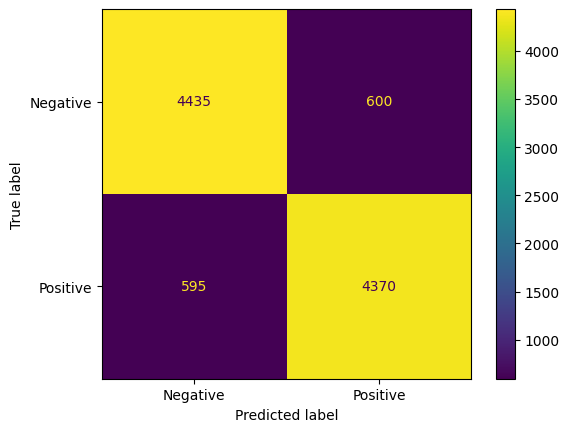

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(lr, bow_X_test, ohe_y_test, values_format='d', display_labels=['Negative', 'Positive']);

In [ ]:
from sklearn.linear_model import SGDClassifier
svm = SGDClassifier(loss='hinge', random_state=42)
svm.fit(bow_X_train,ohe_y_train.ravel())
svm

SGDClassifier(random_state=42)

In [ ]:
# Os nomes seguem os IDs aprendidos no treino: negative=0, positive=1.
# zero_division=0 é convenção para métricas indefinidas, não desempenho medido sem suporte.
# As saídas históricas abaixo podem conservar os nomes antigos invertidos; não foram recalculadas.
y_predict = svm.predict(bow_X_test)
print("SVM Score :",accuracy_score(ohe_y_test , y_predict))
print(classification_report(ohe_y_test.ravel(), y_predict, labels=[0, 1], target_names=lb.classes_.tolist(), zero_division=0))

SVM Score : 0.8734
              precision    recall  f1-score   support

    Positive       0.87      0.88      0.88      5035
    Negative       0.88      0.86      0.87      4965

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000



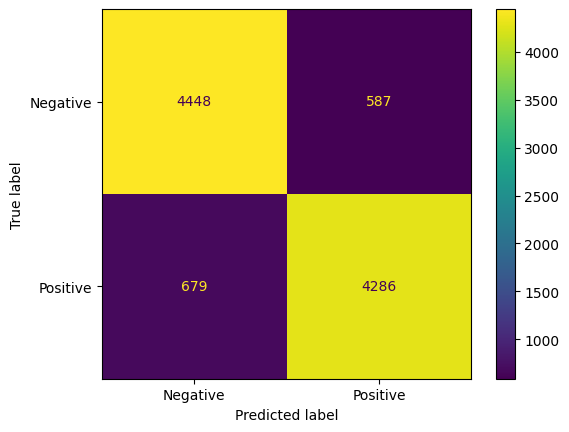

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(svm, bow_X_test, ohe_y_test, values_format='d', display_labels=['Negative', 'Positive']);

In [ ]:
%%time
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer(min_df=1,max_df=1.0,binary=False,ngram_range=(2,2))
bow_X_train = cv.fit_transform(X_train)
bow_X_test = cv.transform(X_test)
print('bow_X_train shape:',bow_X_train.shape)
print('bow_X_test shape:',bow_X_test.shape)

bow_X_train shape: (40000, 2284495)
bow_X_test shape: (10000, 2284495)
CPU times: user 28.4 s, sys: 290 ms, total: 28.7 s
Wall time: 28.8 s


In [ ]:
%%time
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(penalty='l2', max_iter=500, C=1, random_state=42)
lr.fit(bow_X_train,ohe_y_train.ravel())
print(lr)

LogisticRegression(C=1, max_iter=500, random_state=42)
CPU times: user 29.3 s, sys: 1.45 s, total: 30.7 s
Wall time: 20.4 s


In [ ]:
# Os nomes seguem os IDs aprendidos no treino: negative=0, positive=1.
# zero_division=0 é convenção para métricas indefinidas, não desempenho medido sem suporte.
# As saídas históricas abaixo podem conservar os nomes antigos invertidos; não foram recalculadas.
y_predict = lr.predict(bow_X_test)
print("LogReg Score :",accuracy_score(ohe_y_test , y_predict))
print(classification_report(ohe_y_test.ravel(), y_predict, labels=[0, 1], target_names=lb.classes_.tolist(), zero_division=0))

LogReg Score : 0.8758
              precision    recall  f1-score   support

    Positive       0.88      0.87      0.88      5035
    Negative       0.87      0.88      0.88      4965

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



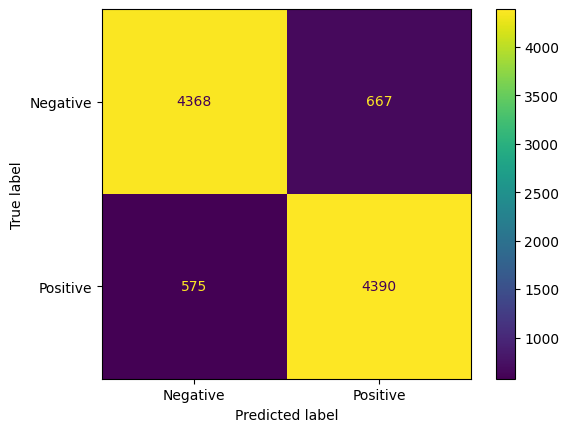

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(lr, bow_X_test, ohe_y_test, values_format='d', display_labels=['Negative', 'Positive']);

In [ ]:
%%time
from sklearn.linear_model import SGDClassifier
svm = SGDClassifier(loss='hinge', random_state=42)
svm.fit(bow_X_train,ohe_y_train.ravel())
print(svm)

SGDClassifier(random_state=42)
CPU times: user 1.52 s, sys: 30.7 ms, total: 1.55 s
Wall time: 2.89 s


In [ ]:
# Os nomes seguem os IDs aprendidos no treino: negative=0, positive=1.
# zero_division=0 é convenção para métricas indefinidas, não desempenho medido sem suporte.
# As saídas históricas abaixo podem conservar os nomes antigos invertidos; não foram recalculadas.
y_predict = svm.predict(bow_X_test)
print("SVM Score :",accuracy_score(ohe_y_test , y_predict))
print(classification_report(ohe_y_test.ravel(), y_predict, labels=[0, 1], target_names=lb.classes_.tolist(), zero_division=0))

SVM Score : 0.8745
              precision    recall  f1-score   support

    Positive       0.88      0.87      0.88      5035
    Negative       0.87      0.88      0.87      4965

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000



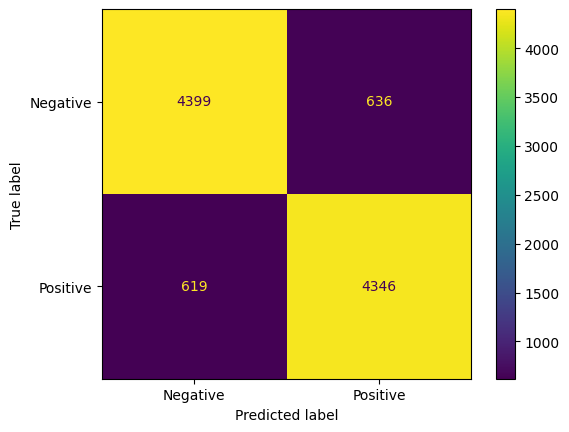

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(svm, bow_X_test, ohe_y_test, values_format='d', display_labels=['Negative', 'Positive']);

In [ ]:
%%time
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer(min_df=1,max_df=1.0,binary=False,ngram_range=(3,3))
bow_X_train = cv.fit_transform(X_train)
bow_X_test = cv.transform(X_test)
print('bow_X_train shape:',bow_X_train.shape)
print('bow_X_test shape:',bow_X_test.shape)

bow_X_train shape: (40000, 4546929)
bow_X_test shape: (10000, 4546929)
CPU times: user 37.1 s, sys: 931 ms, total: 38 s
Wall time: 40.3 s


In [ ]:
%%time
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(penalty='l2', max_iter=500, C=1, random_state=42)
lr.fit(bow_X_train,ohe_y_train.ravel())
print(lr)

LogisticRegression(C=1, max_iter=500, random_state=42)
CPU times: user 23.8 s, sys: 2.9 s, total: 26.7 s
Wall time: 32.1 s


In [ ]:
# Os nomes seguem os IDs aprendidos no treino: negative=0, positive=1.
# zero_division=0 é convenção para métricas indefinidas, não desempenho medido sem suporte.
# As saídas históricas abaixo podem conservar os nomes antigos invertidos; não foram recalculadas.
y_predict = lr.predict(bow_X_test)
print("LogReg Score :",accuracy_score(ohe_y_test , y_predict))
print(classification_report(ohe_y_test.ravel(), y_predict, labels=[0, 1], target_names=lb.classes_.tolist(), zero_division=0))

LogReg Score : 0.7677
              precision    recall  f1-score   support

    Positive       0.85      0.65      0.74      5035
    Negative       0.71      0.89      0.79      4965

    accuracy                           0.77     10000
   macro avg       0.78      0.77      0.76     10000
weighted avg       0.78      0.77      0.76     10000



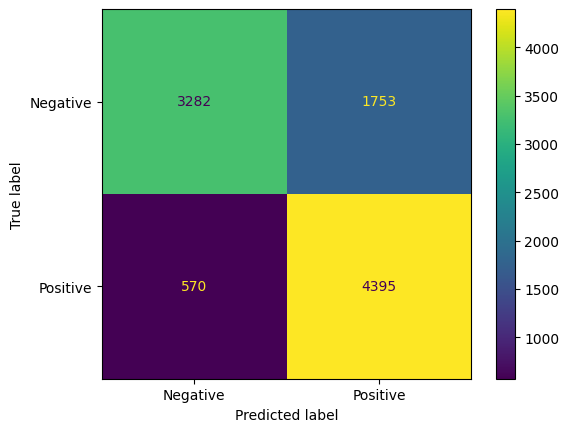

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(lr, bow_X_test, ohe_y_test, values_format='d', display_labels=['Negative', 'Positive']);

In [ ]:
%%time
from sklearn.linear_model import SGDClassifier
svm = SGDClassifier(loss='hinge', random_state=42)
svm.fit(bow_X_train,ohe_y_train.ravel())
print(svm)

SGDClassifier(random_state=42)
CPU times: user 1.44 s, sys: 3.01 ms, total: 1.44 s
Wall time: 1.32 s


In [ ]:
# Os nomes seguem os IDs aprendidos no treino: negative=0, positive=1.
# zero_division=0 é convenção para métricas indefinidas, não desempenho medido sem suporte.
# As saídas históricas abaixo podem conservar os nomes antigos invertidos; não foram recalculadas.
y_predict = svm.predict(bow_X_test)
print("SVM Score :",accuracy_score(ohe_y_test , y_predict))
print(classification_report(ohe_y_test.ravel(), y_predict, labels=[0, 1], target_names=lb.classes_.tolist(), zero_division=0))

SVM Score : 0.7574
              precision    recall  f1-score   support

    Positive       0.87      0.61      0.72      5035
    Negative       0.70      0.91      0.79      4965

    accuracy                           0.76     10000
   macro avg       0.78      0.76      0.75     10000
weighted avg       0.78      0.76      0.75     10000



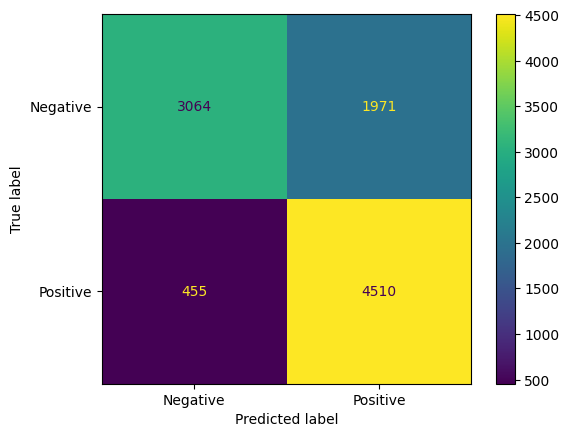

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(svm, bow_X_test, ohe_y_test, values_format='d', display_labels=['Negative', 'Positive']);